# Study EDA — original normal training

Feature-level EDA for Experiment 1 on the **frozen audit split**, mirroring
the production `notebooks/eda.ipynb` visuals. Data comes from the manifest-
checked prepared bundle (`study/artifacts/phase_03_study/`), so the split and
window geometry match the study exactly.

Only original normal training rows are analyzed; no synthetic/augmented-data
EDA (the Phase 1 audit already covers the study specification). The feature
schema is frozen at 25 source features, so this notebook inspects domains and
redundancy rather than selecting features. Figures are saved under
`study/eda/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from cheatdetect.data.feature_schema import SOURCE_FEATURES
from cheatdetect.experiments.experiment_1 import runner
from cheatdetect.experiments.experiment_1.config import StudyConfig
from cheatdetect.utils import _find_project_root

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

HIGH_CORR = 0.85  # production EDA threshold; the study schema is fixed
EDA_DIR = _find_project_root() / "study" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

config = StudyConfig()
study = runner.load_study(config)

## Dataset summary — paired windows per partition

In [2]:
summary = pd.DataFrame(
    [
        {
            "partition": partition,
            "chunks": len(view.parent),
            "anomalous_chunks": int(view.labels.sum()),
            "sessions": view.identities["session_file"].nunique(),
        }
        for partition, view in study.raw.items()
    ]
).set_index("partition")
summary["normal_chunks"] = summary["chunks"] - summary["anomalous_chunks"]
summary["anomalous_pct"] = (
    summary["anomalous_chunks"] / summary["chunks"] * 100
).round(1)
summary

,chunks,anomalous_chunks,sessions,normal_chunks,anomalous_pct
partition,,,,,
train_original,662,0,15,662,0.0
train_synthetic,1324,0,15,1324,0.0
normal_val,197,0,4,197,0.0
mixed_val,196,82,5,114,41.8
mixed_test,366,205,10,161,56.0


## Domain check + zero-variance features (original normal train only)

In [3]:
X_train = study.raw["train_original"].parent[list(SOURCE_FEATURES)]

zero_variance = [
    feature for feature in SOURCE_FEATURES if X_train[feature].var() == 0
]
print(f"Source features: {len(SOURCE_FEATURES)}")
print(f"Zero-variance features: {len(zero_variance)}")
for feature in zero_variance:
    print(f"  - {feature}")
if not zero_variance:
    print("  (none)")

Source features: 25
Zero-variance features: 0
  (none)


## Feature distributions (original normal train only)

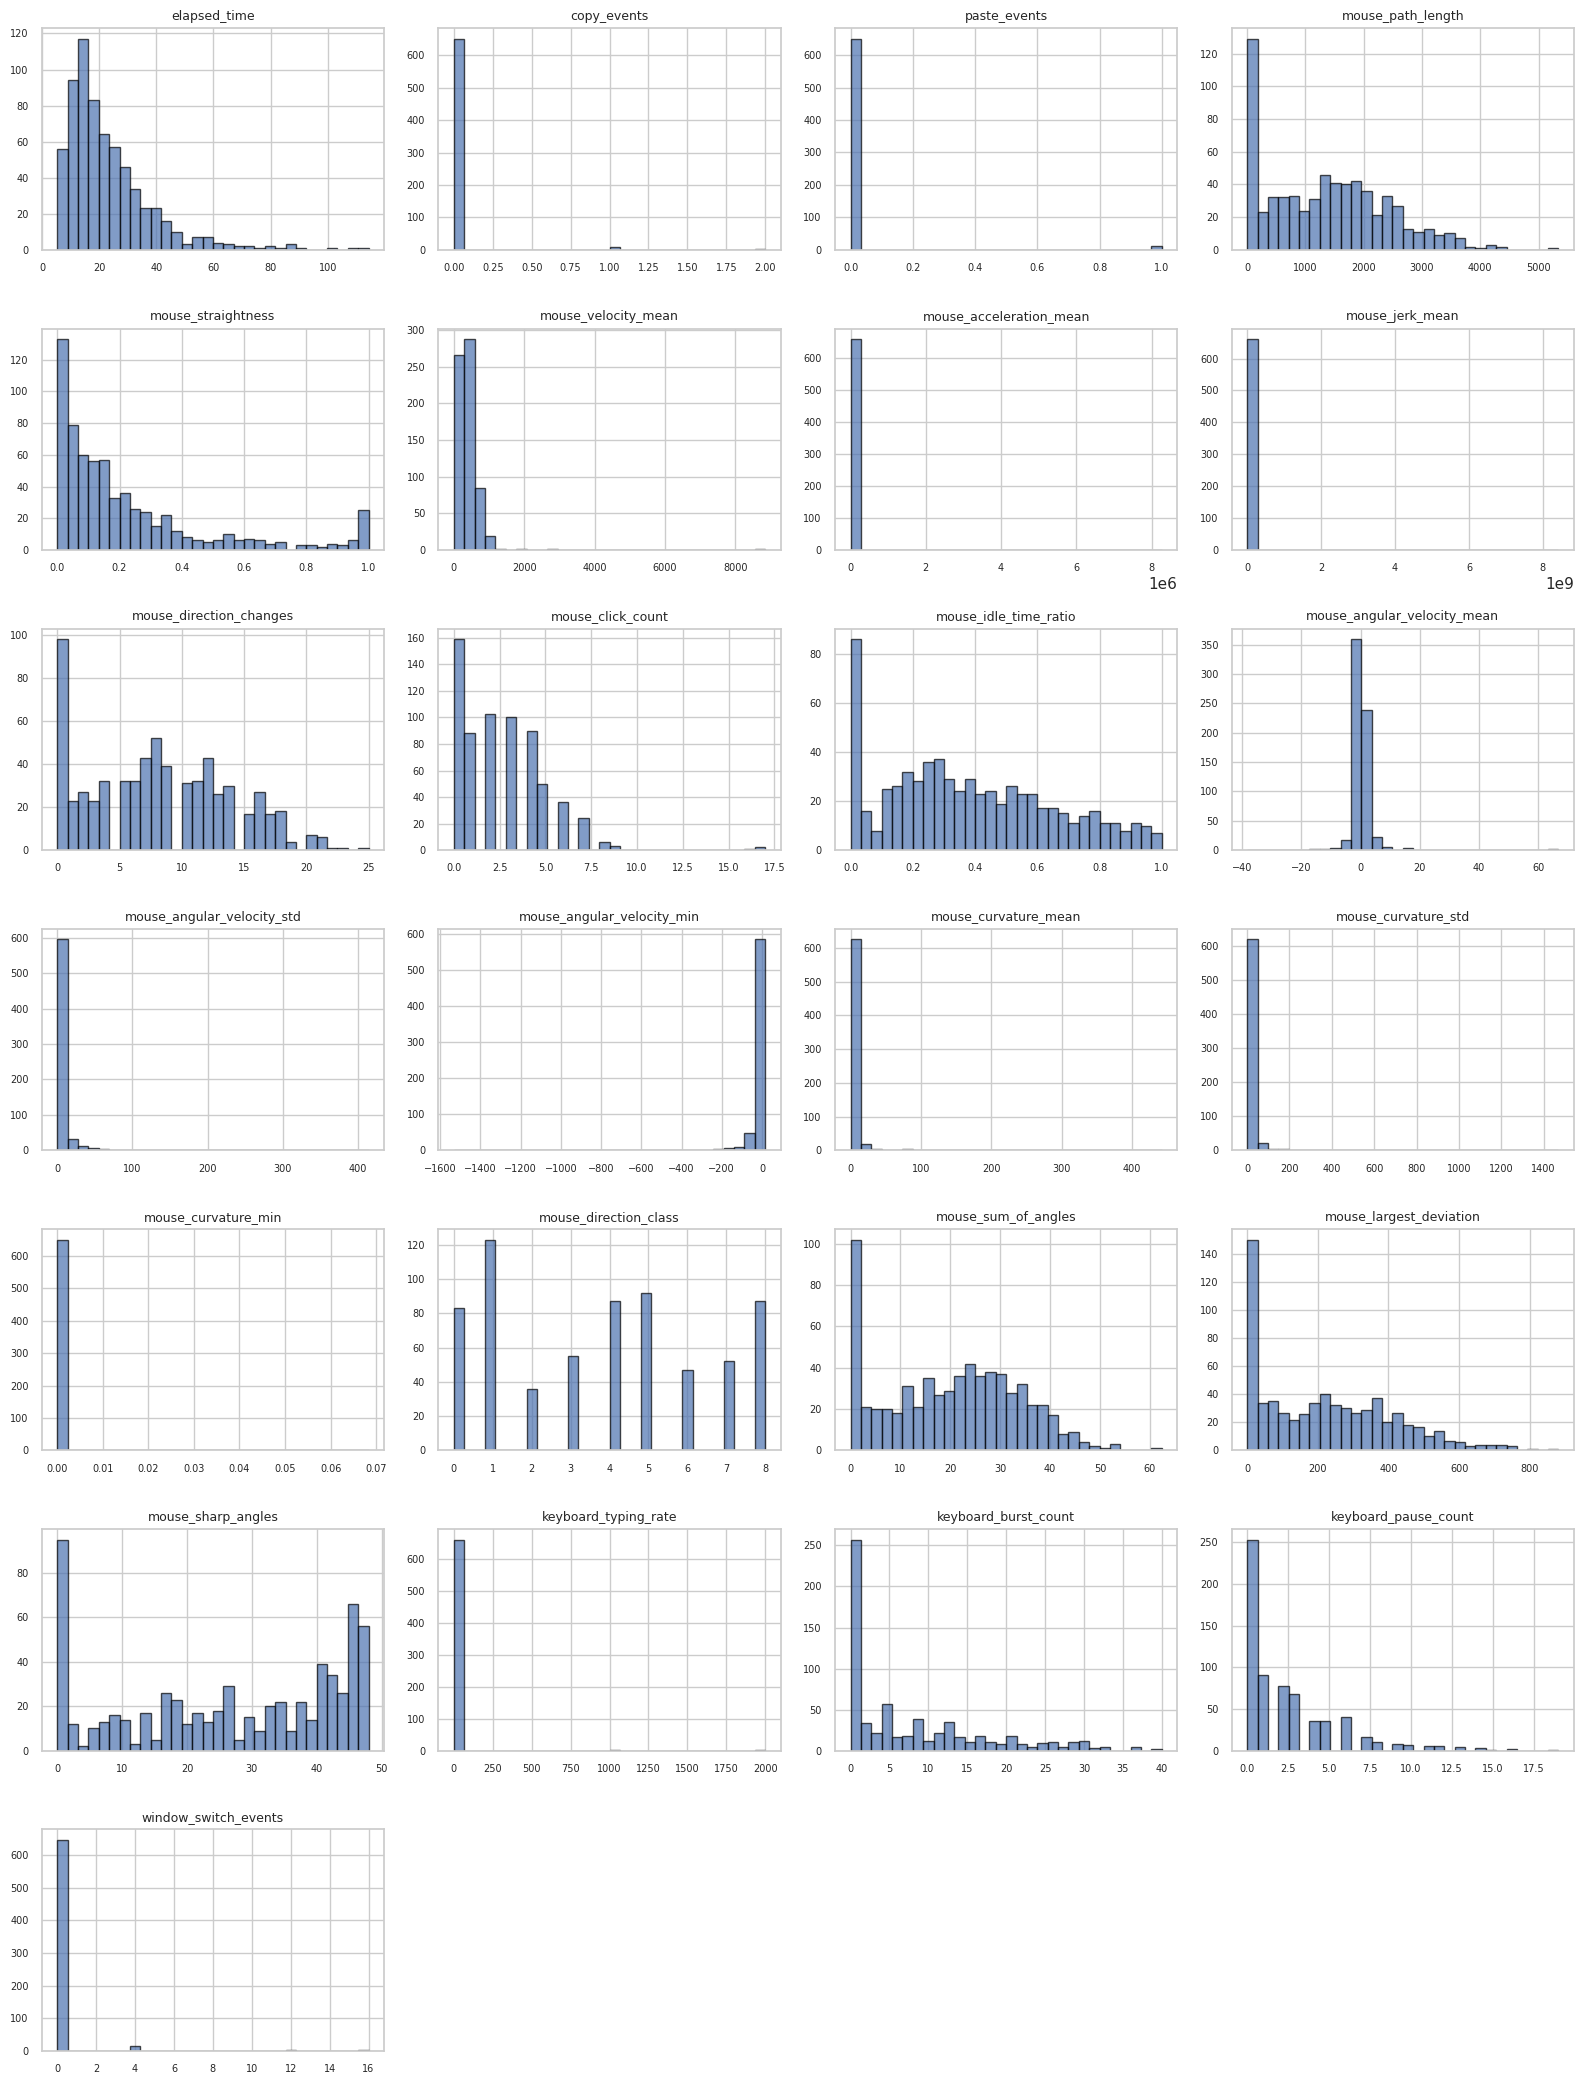

Note: Sparse features (e.g. copy_events, window_switch_events) are normal.
They are valuable discriminators for anomaly detection — not noise.


In [4]:
n_cols = 4
n_rows = (len(SOURCE_FEATURES) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3))
axes = axes.flatten()

for i, feature in enumerate(SOURCE_FEATURES):
    axes[i].hist(X_train[feature].dropna(), bins=30, alpha=0.7, edgecolor="black")
    axes[i].set_title(feature, fontsize=9)
    axes[i].tick_params(labelsize=7)

for j in range(len(SOURCE_FEATURES), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(EDA_DIR / "feature_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

print("Note: Sparse features (e.g. copy_events, window_switch_events) are normal.")
print("They are valuable discriminators for anomaly detection — not noise.")

## Correlation analysis (original normal train only)

=== Correlated Pairs (|r| > 0.85) ===
Found 5 pairs



,feature_1,feature_2,correlation
0,mouse_acceleration_mean,mouse_jerk_mean,0.998840
1,mouse_direction_changes,mouse_sum_of_angles,0.968419
2,mouse_curvature_mean,mouse_curvature_std,0.921288
3,mouse_sum_of_angles,mouse_sharp_angles,0.895912
4,mouse_sharp_angles,keyboard_burst_count,-0.865542


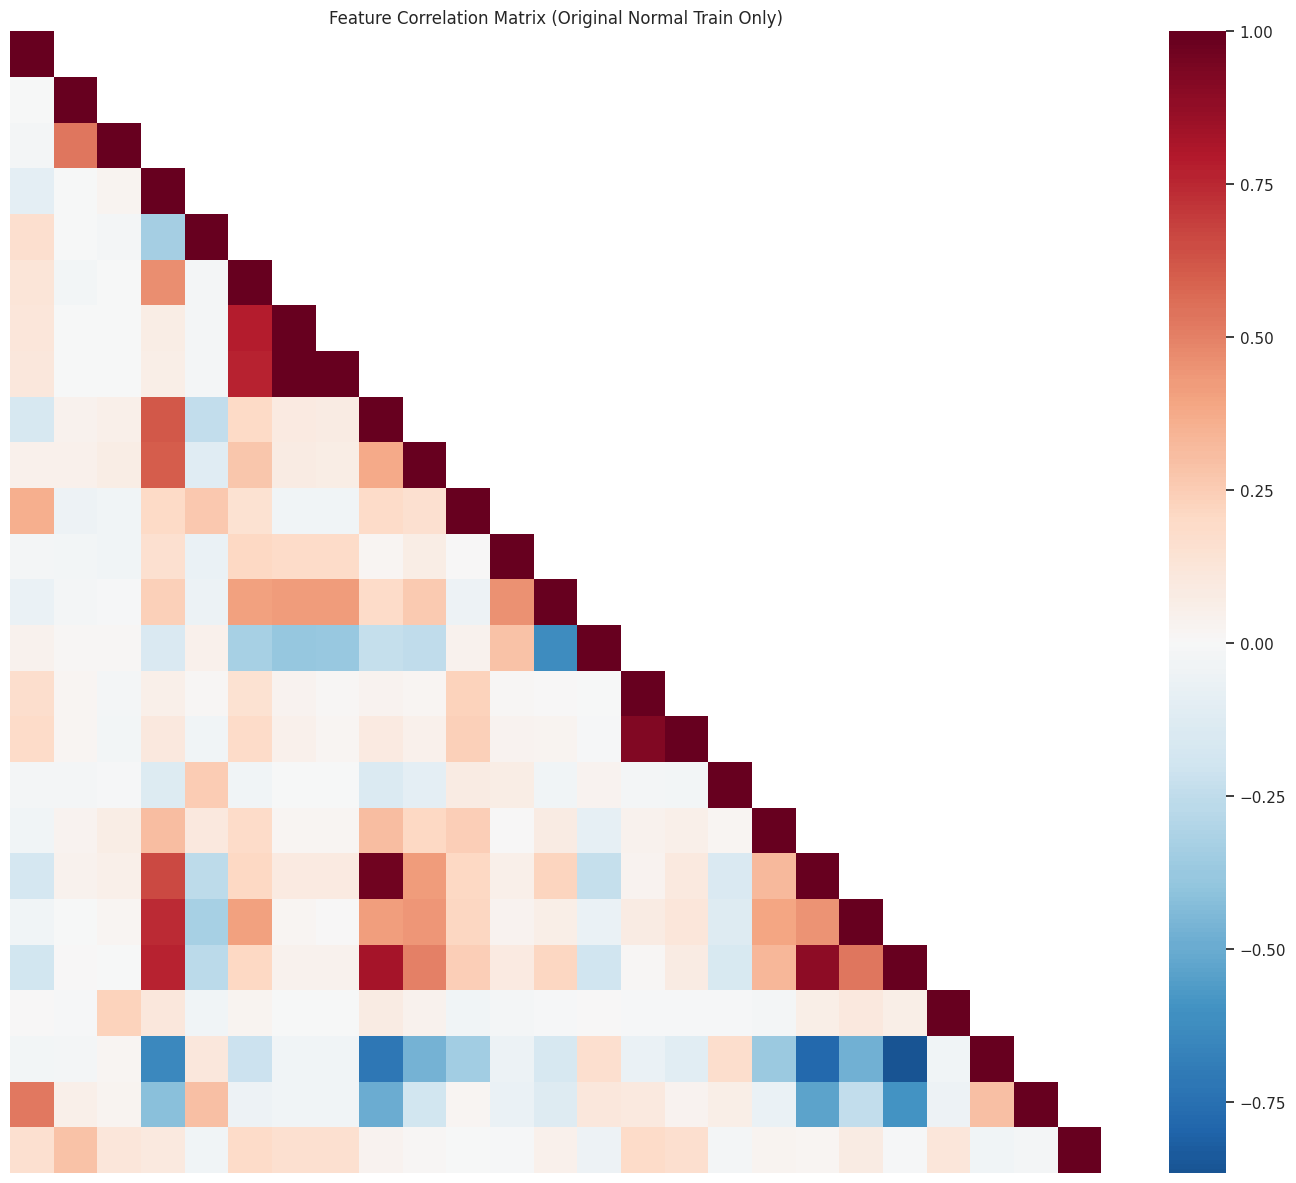

In [5]:
corr = X_train.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

pairs = corr.where(mask).stack()
pairs = (
    pairs[pairs.abs() > HIGH_CORR]
    .rename("correlation")
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2"})
    .sort_values("correlation", key=lambda values: values.abs(), ascending=False)
)
print(f"=== Correlated Pairs (|r| > {HIGH_CORR}) ===")
print(f"Found {len(pairs)} pairs\n")
if len(pairs):
    display(pairs)
else:
    print("None.")

plt.figure(figsize=(14, 12))
sns.heatmap(
    corr, mask=mask, cmap="RdBu_r", center=0,
    xticklabels=False, yticklabels=False,
)
plt.title("Feature Correlation Matrix (Original Normal Train Only)")
plt.tight_layout()
plt.savefig(EDA_DIR / "correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Per-feature summary

In [6]:
max_abs_corr = corr.abs().where(mask).max()
schema_summary = pd.DataFrame(
    {
        "feature": list(SOURCE_FEATURES),
        "zero_variance": [feature in zero_variance for feature in SOURCE_FEATURES],
        "max_abs_correlation": [
            max_abs_corr[feature] for feature in SOURCE_FEATURES
        ],
    }
)
print("The 25-source schema is frozen; correlated pairs are reported above but")
print("redundancy is handled by the audited recipes, not dropped here.")
schema_summary

The 25-source schema is frozen; correlated pairs are reported above but
redundancy is handled by the audited recipes, not dropped here.


,feature,zero_variance,max_abs_correlation
0,elapsed_time,False,NaN
1,copy_events,False,0.005052
2,paste_events,False,0.532239
3,mouse_path_length,False,0.098039
4,mouse_straightness,False,0.335387
5,mouse_velocity_mean,False,0.462884
6,mouse_acceleration_mean,False,0.785449
7,mouse_jerk_mean,False,0.998840
8,mouse_direction_changes,False,0.614179
9,mouse_click_count,False,0.603739
